# Проект «Моделирование жидкосцинтилляционного детектора». Данный Jupiter Notebook содержит решения задач 1-4.
## Задача 2. Создание источника фотонов

В этом ноутбуке реализован программный источник сцинтилляционных фотонов. Он принимает энергию события $E$, рассчитывает число фотонов по заданному световыходу и генерирует начальные направления их движения.

**Параметр из условия:**
$$
Y=10\,000\ \frac{\text{фотонов}}{\text{МэВ}}.
$$

**Физические допущения задачи:**
1. Излучение изотропно.
2. Средний выход фотонов линейно зависит от энергии:
   $$
N_\gamma = YE.
$$

В рамках этой задачи моделируются только начальные направления фотонов. Перенос фотонов в жидкости, поглощение, рассеяние и регистрация фотоумножителями относятся к следующим этапам моделирования.

## 1. Геометрия детектора из предыдущей задачи

Сохраняем модель сферического детектора и расположение фотоумножителей из предоставленного ноутбука предыдущей задачи. Это позволяет далее использовать общий проект в одном окружении. Для решения задачи 2 наличие `k3d` необязательно: библиотека нужна только для интерактивной 3D-визуализации геометрии.

**Зависимости:** `numpy`, `matplotlib`, `k3d`. Для интерактивной 3D-визуализации обязательно установите K3D, если он отсутствует: `%pip install k3d`. После установки перезапустите ядро и выполните ноутбук сверху вниз.

In [27]:
%pip install k3d

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\Public\Documents\Макар 07_10_2026 22_57\Учёба\ФНАФЧ\Коды\.venv\Scripts\python.exe -m pip install --upgrade pip


In [28]:
"""
Detector: сферический детектор с N фотоумножителями.

Параметры по умолчанию:
    R = 2.0 м   — радиус поверхности детектора
    N = 40      — число фотоумножителей
    r = 0.10 м  — радиус одного фотоумножителя (10 см)
    a = 0.5     — коэффициент подъёма при визуализации (чтобы ФЭУ были видны над сферой)

Расположение ФЭУ — по спирали Фибоначчи (равномерно по сфере).
"""

import numpy as np

try:
    import k3d
except ImportError:
    k3d = None


# ---------- вспомогательные функции ----------

def _uv_sphere(R, n_u=72, n_v=36):
    """Сетка UV-сферы: возвращает (vertices, indices)."""
    u = np.linspace(0.0, 2.0 * np.pi, n_u, endpoint=False)
    v = np.linspace(0.0, np.pi, n_v)
    U, V = np.meshgrid(u, v)
    X = R * np.sin(V) * np.cos(U)
    Y = R * np.sin(V) * np.sin(U)
    Z = R * np.cos(V)
    verts = np.stack([X, Y, Z], axis=-1).reshape(-1, 3).astype(np.float32)

    idx = []
    for i in range(n_v - 1):
        for j in range(n_u):
            j2 = (j + 1) % n_u
            a = i * n_u + j
            b = i * n_u + j2
            c = (i + 1) * n_u + j
            d = (i + 1) * n_u + j2
            idx.append([a, c, b])
            idx.append([b, c, d])
    return verts, np.asarray(idx, dtype=np.uint32)


def _cap_mesh(direction, R, theta, n=24):
    """
    Сферическая «шапочка» радиуса R с угловым полураствором theta
    вокруг направления direction. Возвращает (vertices, indices).
    """
    d = direction / np.linalg.norm(direction)
    tmp = np.array([1.0, 0.0, 0.0])
    if abs(np.dot(d, tmp)) > 0.9:
        tmp = np.array([0.0, 1.0, 0.0])
    e1 = np.cross(d, tmp); e1 /= np.linalg.norm(e1)
    e2 = np.cross(d, e1)

    verts = [R * d]
    for phi in np.linspace(0.0, 2.0 * np.pi, n, endpoint=False):
        p = (R * np.cos(theta) * d
             + R * np.sin(theta) * (np.cos(phi) * e1 + np.sin(phi) * e2))
        verts.append(p)
    verts = np.asarray(verts, dtype=np.float32)

    idx = []
    for i in range(1, n + 1):
        j = i + 1 if i < n else 1
        idx.append([0, i, j])
    return verts, np.asarray(idx, dtype=np.uint32)


# ---------- основной класс ----------

class Detector:
    def __init__(self, R=2.0, N=40, r=0.10, a=0.5):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r)
        self.a = float(a)

        # Угловой радиус одной «шапочки» ФЭУ, видимой из центра сферы
        self.theta_pmt = float(np.arcsin(self.r / self.R))

        # Равномерное расположение ФЭУ (спираль Фибоначчи)
        self.pmt_directions = self._fibonacci_sphere(self.N)      # (N, 3) — единичные векторы
        self.pmt_centers = self.pmt_directions * self.R            # (N, 3) — центры на сфере

        # Структура для хранения информации о каждом ФЭУ
        self.pmts = [
            {
                "id": i,
                "direction": self.pmt_directions[i],
                "center": self.pmt_centers[i],
                "radius": self.r,
                "theta": self.theta_pmt,
            }
            for i in range(self.N)
        ]

    # ---- генерация точек ----
    @staticmethod
    def _fibonacci_sphere(N):
        idx = np.arange(N, dtype=float)
        phi = np.pi * (3.0 - np.sqrt(5.0))     # золотой угол
        y = 1.0 - 2.0 * (idx + 0.5) / N
        r_xy = np.sqrt(np.clip(1.0 - y * y, 0.0, 1.0))
        theta = phi * idx
        x = np.cos(theta) * r_xy
        z = np.sin(theta) * r_xy
        return np.stack([x, y, z], axis=1)

    # ---- геометрическая проверка ----
    def belongs_to_pmt(self, point):
        """
        Принадлежит ли точка (x, y, z) поверхности какому-либо ФЭУ?
        Возвращает id ФЭУ или None.
        """
        p = np.asarray(point, dtype=float)
        norm = np.linalg.norm(p)
        if norm == 0.0:
            return None
        p_dir = p / norm
        cos_ang = self.pmt_directions @ p_dir                # (N,)
        angles = np.arccos(np.clip(cos_ang, -1.0, 1.0))
        k = int(np.argmin(angles))
        return k if angles[k] <= self.theta_pmt else None

    # ---- визуализация ----
    def build_plot(self, sphere_color=0x3050a0, pmt_color=0xffcc00):
        if k3d is None:
            raise ImportError(
                "Для 3D-визуализации установите k3d: %pip install k3d"
            )
        plot = k3d.plot(name="Detector")

        # 1) Поверхность детектора (полупрозрачная сфера)
        verts, indices = _uv_sphere(self.R)
        plot += k3d.mesh(verts, indices,
                         color=sphere_color, opacity=0.15,
                         wireframe=False)

        # 2) Фотоумножители — единый меш из сферических «шапочек»
        all_v, all_i = [], []
        offset = 0
        for pmt in self.pmts:
            v, i = _cap_mesh(pmt["direction"],
                             self.R + self.a * self.r,   # слегка приподняты для наглядности
                             self.theta_pmt,
                             n=24)
            all_v.append(v)
            all_i.append(i + offset)
            offset += len(v)

        plot += k3d.mesh(np.vstack(all_v), np.vstack(all_i),
                         color=pmt_color, wireframe=False)
        return plot

In [29]:
import matplotlib.pyplot as plt


### Проверка геометрии детектора (необязательный блок)

Если пакет `k3d` установлен, следующая ячейка построит 3D-модель. В противном случае код сообщит, как установить пакет; расчёты источника от него не зависят.

In [30]:
detector = Detector(R=2.0, N=40, r=0.10, a=0.5)

print(f"Радиус детектора: {detector.R:.2f} м")
print(f"Количество фотоумножителей: {detector.N}")
print(f"Радиус фотокатода: {detector.r:.2f} м")
print(f"Угловой радиус фотокатода: {detector.theta_pmt:.5f} рад")

if k3d is not None:
    detector_plot = detector.build_plot()
    detector_plot
else:
    print("3D-визуализация пропущена: установите k3d командой %pip install k3d.")

Радиус детектора: 2.00 м
Количество фотоумножителей: 40
Радиус фотокатода: 0.10 м
Угловой радиус фотокатода: 0.05002 рад


## 2. Физическая модель источника

### 2.1. Число фотонов

Для события с энергией $E$ (в МэВ) число испускаемых фотонов задаётся линейным законом:
$$
N_\gamma = YE.
$$

Поскольку число фотонов — целое, в основном режиме используется округление до ближайшего целого:
$$
N_\gamma = \operatorname{round}(YE).
$$

Например, для $E=1$ МэВ источник генерирует 10 000 фотонов.

### 2.2. Изотропное распределение направлений

Направление фотона зададим сферическими углами $\theta$ и $\varphi$:
$$
\begin{aligned}
n_x &= \sin\theta\cos\varphi,\\
n_y &= \sin\theta\sin\varphi,\\
n_z &= \cos\theta.
\end{aligned}
$$

Для равномерного распределения по телесному углу необходимо разыгрывать:
$$
\varphi\sim U(0,2\pi),\qquad
\mu=\cos\theta\sim U(-1,1).
$$

**Ключевой момент:** полярный угол $\theta$ нельзя разыгрывать равномерно. При изотропном излучении равномерно распределён именно $\cos\theta$. Такой выбор обеспечивает постоянную вероятность попадания в равные телесные углы.

## 3. Реализация класса `Source`

Класс разделяет две операции: определение числа фотонов и генерацию их направлений. Все направления возвращаются в виде единичных декартовых векторов. Генератор случайных чисел можно передать извне для воспроизводимости результатов.

In [31]:
from typing import Optional

YIELD_PER_MEV = 10_000


class Source:
    """Источник изотропного сцинтилляционного излучения.

    Parameters
    ----------
    Y : float
        Световыход в фотонах/МэВ.

    Methods
    -------
    photon_count(E)
        Возвращает число фотонов для энергии E (МэВ).
    generate_directions(E, rng=None)
        Генерирует массив единичных направлений формы (N_gamma, 3).
    """

    def __init__(self, Y: float = YIELD_PER_MEV) -> None:
        if not np.isfinite(Y) or Y <= 0:
            raise ValueError("Y должен быть конечным положительным числом.")
        self.Y = float(Y)

    def photon_count(self, E: float) -> int:
        """Число фотонов по линейному закону N_gamma = Y * E."""
        if not np.isfinite(E) or E < 0:
            raise ValueError("Энергия E должна быть конечной и неотрицательной.")
        return int(np.rint(self.Y * float(E)))

    def generate_directions(
        self,
        E: float,
        rng: Optional[np.random.Generator] = None,
    ) -> np.ndarray:
        """Сгенерировать изотропные начальные направления фотонов.

        Parameters
        ----------
        E : float
            Энергия события в МэВ.
        rng : numpy.random.Generator, optional
            Генератор случайных чисел. При отсутствии создаётся новый.

        Returns
        -------
        numpy.ndarray
            Массив формы (N_gamma, 3). Каждая строка — единичный
            вектор направления (n_x, n_y, n_z).
        """
        rng = np.random.default_rng() if rng is None else rng
        n_photons = self.photon_count(E)

        # Изотропность на сфере: phi равномерно на [0, 2*pi),
        # cos(theta) равномерно на [-1, 1].
        phi = rng.uniform(0.0, 2.0 * np.pi, size=n_photons)
        cos_theta = rng.uniform(-1.0, 1.0, size=n_photons)
        sin_theta = np.sqrt(np.maximum(0.0, 1.0 - cos_theta**2))

        directions = np.column_stack((
            sin_theta * np.cos(phi),
            sin_theta * np.sin(phi),
            cos_theta,
        ))
        return directions


## 4. Пример использования

Рассмотрим событие с энергией 1 МэВ. Зафиксируем `seed`, чтобы при повторном запуске получить те же направления.

In [32]:
source = Source(Y=10_000)
rng = np.random.default_rng(seed=2026)

energy = 1.0  # МэВ
directions = source.generate_directions(energy, rng=rng)

print(f"Энергия события:       {energy:.3f} МэВ")
print(f"Световыход:            {source.Y:,.0f} фотонов/МэВ")
print(f"Число фотонов:         {len(directions):,}")
print(f"Размер массива:        {directions.shape}")
print(f"Первые пять направлений:\n{directions[:5]}")

Энергия события:       1.000 МэВ
Световыход:            10,000 фотонов/МэВ
Число фотонов:         10,000
Размер массива:        (10000, 3)
Первые пять направлений:
[[ 0.23106289  0.48262279  0.8447989 ]
 [-0.506212   -0.6112259   0.60840144]
 [-0.97848324  0.20411952  0.03009613]
 [-0.62890714  0.66551143  0.40195813]
 [-0.38579199  0.49789382 -0.77670219]]


## 5. Численная верификация

Проверим три свойства реализации:
- число фотонов соответствует заданному линейному закону;
- каждое направление имеет единичную длину;
- при изотропном распределении средние компоненты направлений близки к нулю.

In [33]:
# 1. Проверка количества фотонов
expected_count = int(round(source.Y * energy))
assert directions.shape == (expected_count, 3)

# 2. Проверка единичной длины всех векторов
norms = np.linalg.norm(directions, axis=1)
assert np.allclose(norms, 1.0, atol=1e-12)

# 3. Для изотропного распределения среднее направление должно быть около нуля
mean_direction = directions.mean(axis=0)

print(f"Ожидаемое число фотонов: {expected_count:,}")
print(f"Фактическое число фотонов: {len(directions):,}")
print(f"Максимальное отклонение нормы от 1: {np.max(np.abs(norms - 1)):.3e}")
print(f"Средний вектор направлений: {mean_direction}")

assert np.all(np.abs(mean_direction) < 0.03)
print("\nВсе проверки успешно пройдены.")

Ожидаемое число фотонов: 10,000
Фактическое число фотонов: 10,000
Максимальное отклонение нормы от 1: 2.220e-16
Средний вектор направлений: [-0.00425032 -0.00413056 -0.0056235 ]

Все проверки успешно пройдены.


## 6. Проверка изотропности распределения

Для изотропного источника величины $\cos\theta$ и $\varphi$ равномерны на интервалах $[-1,1]$ и $[0,2\pi)$ соответственно. Гистограммы сравниваются с теоретическими плотностями.

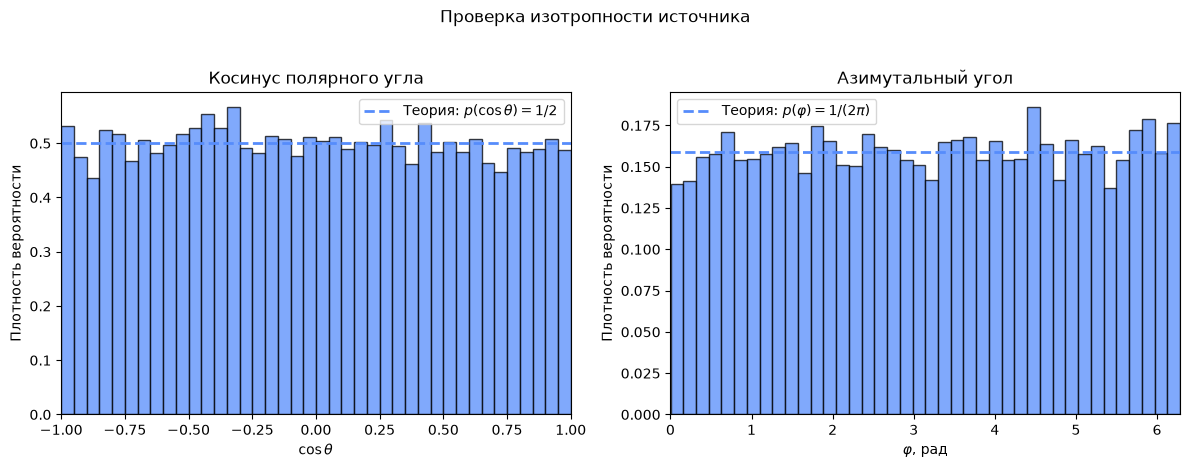

In [34]:
cos_theta = directions[:, 2]
phi = np.mod(np.arctan2(directions[:, 1], directions[:, 0]), 2 * np.pi)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(cos_theta, bins=40, density=True, alpha=0.75, edgecolor="black")
axes[0].axhline(0.5, linestyle="--", linewidth=2,
                label=r"Теория: $p(\cos\theta)=1/2$")
axes[0].set(
    xlabel=r"$\cos\theta$",
    ylabel="Плотность вероятности",
    title="Косинус полярного угла",
    xlim=(-1, 1),
)
axes[0].legend()

axes[1].hist(phi, bins=40, density=True, alpha=0.75, edgecolor="black")
axes[1].axhline(1 / (2 * np.pi), linestyle="--", linewidth=2,
                label=r"Теория: $p(\varphi)=1/(2\pi)$")
axes[1].set(
    xlabel=r"$\varphi$, рад",
    ylabel="Плотность вероятности",
    title="Азимутальный угол",
    xlim=(0, 2 * np.pi),
)
axes[1].legend()

fig.suptitle("Проверка изотропности источника", y=1.03)
plt.tight_layout()
plt.show()

## 7. Зависимость выхода фотонов от энергии

Проверим линейный закон для нескольких энергий. Это тест детерминированной модели, в которой число фотонов округляется до целого.

E =  0.1 МэВ -> N_gamma =   1,000
E =  0.5 МэВ -> N_gamma =   5,000
E =  1.0 МэВ -> N_gamma =  10,000
E =  2.0 МэВ -> N_gamma =  20,000
E =  5.0 МэВ -> N_gamma =  50,000


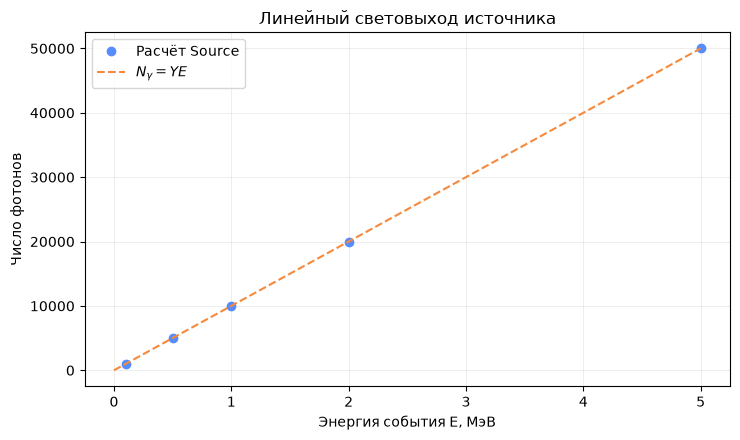

In [35]:
energies = np.array([0.1, 0.5, 1.0, 2.0, 5.0])
counts = np.array([source.photon_count(E) for E in energies])

for E, count in zip(energies, counts):
    print(f"E = {E:4.1f} МэВ -> N_gamma = {count:>7,d}")

energy_grid = np.linspace(0.0, energies.max(), 200)
plt.figure(figsize=(7.5, 4.5))
plt.plot(energies, counts, "o", label="Расчёт Source")
plt.plot(energy_grid, source.Y * energy_grid, "--", label=r"$N_\gamma=YE$")
plt.xlabel("Энергия события E, МэВ")
plt.ylabel("Число фотонов")
plt.title("Линейный световыход источника")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Итог

Реализован класс `Source` со световыходом $Y=10\,000$ фотонов/МэВ.

Для заданной энергии $E$ метод `generate_directions`:
1. рассчитывает число фотонов $N_\gamma=\operatorname{round}(YE)$;
2. генерирует для каждого фотона изотропное направление;
3. возвращает массив единичных векторов $(n_x,n_y,n_z)$.

Изотропность обеспечивается равномерной генерацией азимутального угла $\varphi$ и косинуса полярного угла $\cos\theta$. Численные тесты проверяют размер массива, нормировку направлений и статистическую симметрию распределения.

**Границы модели:** в соответствии с формулировкой задачи источник задаёт только начальные направления фотонов. Время испускания, координаты рождения, спектр длин волн, перенос света, отражение, поглощение и отклик фотоумножителей здесь не моделируются.

# Задача 3. Распространение и детектирование света

В этой части используется геометрия детектора и источник фотонов, реализованные выше.

Для каждого фотона:
1. задаётся точка рождения $\mathbf{x}_0=(x,y,z)$ и единичное направление $\mathbf{n}=(n_x,n_y,n_z)$;
2. вычисляется пересечение луча со сферической границей радиуса $R$;
3. определяется, попала ли точка пересечения на фотокатод одного из ФЭУ;
4. если фотон попал на фотокатод, число фотоэлектронов разыгрывается из распределения Пуассона со средним $a$.

Упрощения строго соответствуют условию: рассеянием и поглощением в жидкости пренебрегаем; фотон полностью поглощается при достижении границы. Отражённые и повторно испущенные фотоны не рассматриваются.

## 9. Геометрия пересечения луча со сферой

Траектория фотона:
$$
\mathbf{x}(t)=\mathbf{x}_0+t\mathbf{n},\qquad t\geq0.
$$
На границе сферы $|\mathbf{x}(t)|=R$. Решение квадратного уравнения:
$$
t=-\mathbf{x}_0\cdot\mathbf{n}
+\sqrt{(\mathbf{x}_0\cdot\mathbf{n})^2+R^2-|\mathbf{x}_0|^2}.
$$
Берём положительный корень, соответствующий первому пересечению границы в направлении движения. Точка попадания равна $\mathbf{x}_{hit}=\mathbf{x}_0+t\mathbf{n}$.

Для определения ФЭУ используем сферические фотокатоды из модели детектора: фотон попадает на ФЭУ, если угол между направлением на точку попадания и осью фотокатода не превышает `detector.theta_pmt`. Если ни один фотокатод не покрывает эту точку, фотон считается не зарегистрированным.

In [36]:
def intersect_sphere(
    origin: np.ndarray,
    direction: np.ndarray,
    radius: float,
) -> tuple[float, np.ndarray]:
    """Первое пересечение луча с поверхностью сферы с центром в начале координат.

    Parameters
    ----------
    origin : array-like, shape (3,)
        Точка рождения фотона внутри сферы.
    direction : array-like, shape (3,)
        Направление движения фотона (нормируется внутри функции).
    radius : float
        Радиус сферы.

    Returns
    -------
    distance : float
        Путь от origin до границы.
    hit_point : ndarray, shape (3,)
        Координаты точки пересечения.
    """
    origin = np.asarray(origin, dtype=float)
    direction = np.asarray(direction, dtype=float)

    if origin.shape != (3,) or direction.shape != (3,):
        raise ValueError("origin и direction должны быть векторами длины 3.")
    if not np.all(np.isfinite(origin)) or not np.all(np.isfinite(direction)):
        raise ValueError("Координаты и направление должны быть конечными.")
    if not np.isfinite(radius) or radius <= 0:
        raise ValueError("Радиус сферы должен быть положительным.")
    if np.linalg.norm(origin) >= radius:
        raise ValueError("Источник должен находиться строго внутри детектора.")

    norm = np.linalg.norm(direction)
    if norm == 0:
        raise ValueError("Нулевое направление фотона недопустимо.")
    n = direction / norm

    projection = float(np.dot(origin, n))
    discriminant = projection**2 + radius**2 - float(np.dot(origin, origin))
    distance = -projection + np.sqrt(max(discriminant, 0.0))
    hit_point = origin + distance * n
    return float(distance), hit_point


def find_pmt_at_hit(detector: Detector, hit_point: np.ndarray):
    """Вернуть индекс ФЭУ, покрывающего точку попадания, или None."""
    hit_point = np.asarray(hit_point, dtype=float)
    if hit_point.shape != (3,) or np.linalg.norm(hit_point) == 0:
        raise ValueError("Некорректная точка попадания.")
    hit_direction = hit_point / np.linalg.norm(hit_point)
    cos_angles = detector.pmt_directions @ hit_direction
    # Сравнение через cos избегает вычисления arccos для всех ФЭУ.
    threshold = np.cos(detector.theta_pmt)
    pmt_index = int(np.argmax(cos_angles))
    return pmt_index if cos_angles[pmt_index] >= threshold else None


## 10. Модель фотоумножителя и статистика фотоэлектронов

Число фотоэлектронов при попадании фотона на фотокатод задано распределением Пуассона:
$$
N_{pe}\sim\operatorname{Poisson}(a),\qquad
P(N_{pe}=k)=\frac{a^k e^{-a}}{k!}.
$$

Метод генерации фотоэлектронов логично относится к классу `Photomultiplier`, а не к `Source` или `Detector`: это отклик конкретного фотокатода на попавший на него фотон. Геометрический поиск фотокатода остаётся ответственностью `Detector`.

In [37]:
class Photomultiplier:
    """Модель отклика одного фотокатода на попавший фотон."""

    def __init__(self, mean_photoelectrons: float, pmt_id: int) -> None:
        if not np.isfinite(mean_photoelectrons) or mean_photoelectrons < 0:
            raise ValueError("Среднее число фотоэлектронов a должно быть >= 0.")
        self.mean_photoelectrons = float(mean_photoelectrons)
        self.pmt_id = int(pmt_id)

    def generate_photoelectrons(
        self,
        rng: np.random.Generator,
    ) -> int:
        """Разыграть число фотоэлектронов из Poisson(a)."""
        return int(rng.poisson(self.mean_photoelectrons))


## 11. Полное моделирование одного события

Функция ниже моделирует все фотоны события, распределяет фотоэлектроны по каналам ФЭУ и сохраняет геометрию траекторий для последующей визуализации. Фотоэлектроны генерируются только для фотонов, попавших на фотокатод.

In [38]:
def simulate_event(
    detector: Detector,
    source: Source,
    energy_mev: float,
    origin=(0.0, 0.0, 0.0),
    a: float = 0.5,
    seed: int = 2026,
):
    """Полный цикл: источник -> пересечение сферы -> ФЭУ -> фотоэлектроны."""
    origin = np.asarray(origin, dtype=float)
    if origin.shape != (3,) or not np.all(np.isfinite(origin)):
        raise ValueError("origin должен быть конечным вектором длины 3.")
    if np.linalg.norm(origin) >= detector.R:
        raise ValueError("Источник должен находиться внутри детектора.")

    rng = np.random.default_rng(seed)
    directions = source.generate_directions(energy_mev, rng=rng)
    n_photons = len(directions)

    pmt_models = [
        Photomultiplier(mean_photoelectrons=a, pmt_id=i)
        for i in range(detector.N)
    ]

    hit_points = np.empty((n_photons, 3), dtype=float)
    path_lengths = np.empty(n_photons, dtype=float)
    pmt_indices = np.full(n_photons, -1, dtype=int)
    photoelectrons = np.zeros(n_photons, dtype=int)
    pmt_counts = np.zeros(detector.N, dtype=int)

    for i, direction in enumerate(directions):
        distance, point = intersect_sphere(origin, direction, detector.R)
        path_lengths[i] = distance
        hit_points[i] = point

        pmt_id = find_pmt_at_hit(detector, point)
        if pmt_id is not None:
            pmt_indices[i] = pmt_id
            npe = pmt_models[pmt_id].generate_photoelectrons(rng)
            photoelectrons[i] = npe
            pmt_counts[pmt_id] += npe

    return {
        "origin": origin,
        "directions": directions,
        "hit_points": hit_points,
        "path_lengths": path_lengths,
        "pmt_indices": pmt_indices,
        "photoelectrons": photoelectrons,
        "pmt_counts": pmt_counts,
        "total_photoelectrons": int(photoelectrons.sum()),
        "detected_photons": int(np.count_nonzero(pmt_indices >= 0)),
        "n_photons": n_photons,
    }


## 12. Запуск моделирования: событие 1 МэВ в центре

Используем параметры детектора, заданные выше (`R=2 м`, `N=40`, `r=0.10 м`), и среднее число фотоэлектронов `a=0.5` на один попавший фотон. Фиксированный seed обеспечивает воспроизводимый пример.

In [39]:
EVENT_ENERGY_MEV = 1.0
PHOTOELECTRON_MEAN = 0.5
EVENT_ORIGIN = (0.0, 0.0, 0.0)

event = simulate_event(
    detector=detector,
    source=source,
    energy_mev=EVENT_ENERGY_MEV,
    origin=EVENT_ORIGIN,
    a=PHOTOELECTRON_MEAN,
    seed=2026,
)

print(f"Энергия события:                  {EVENT_ENERGY_MEV:.2f} МэВ")
print(f"Испущено фотонов:                 {event['n_photons']:,}")
print(f"Фотонов, попавших на фотокатоды:   {event['detected_photons']:,}")
print(f"Геометрическая эффективность:     {event['detected_photons']/event['n_photons']:.4%}")
print(f"Полное число фотоэлектронов:       {event['total_photoelectrons']:,}")
print(f"Среднее число фотоэлектронов/ФЭУ:  {event['pmt_counts'].mean():.3f}")
print(f"Максимум на одном ФЭУ:             {event['pmt_counts'].max()}")

Энергия события:                  1.00 МэВ
Испущено фотонов:                 10,000
Фотонов, попавших на фотокатоды:   237
Геометрическая эффективность:     2.3700%
Полное число фотоэлектронов:       107
Среднее число фотоэлектронов/ФЭУ:  2.675
Максимум на одном ФЭУ:             8


## 13. Сравнение с ожидаемым полным зарядом

В условии предложено сравнить результат с выражением
$$
Q_{given}=aY\frac{Nr^2}{R^2}.
$$
Здесь $Q$ измеряется в фотоэлектронах (при единичном заряде одного фотоэлектрона).

В данной геометрической реализации фотокатоды — сферические шапочки с угловым радиусом $\theta=\arcsin(r/R)$. Их точная доля телесного угла для одного ФЭУ:
$$
f_1=\frac{1-\cos\theta}{2}.
$$
Для неперекрывающихся одинаковых ФЭУ ожидаемое число фотоэлектронов:
$$
Q_{geom}=aYE\,Nf_1.
$$
При $r\ll R$:
$$
Q_{geom}\simeq aYE\frac{Nr^2}{4R^2}.
$$

**Обратите внимание:** в записанной в условии формуле $Q_{given}$ отсутствует множитель $1/4$, который следует из отношения площади фотокатодов к площади сферы $4\pi R^2$. Поэтому ниже приводятся оба значения: буквальная формула из задания и оценка, соответствующая реализованной геометрии. Это позволяет увидеть и объяснить возможное расхождение, а не подгонять симуляцию под формулу.

In [40]:
theta = detector.theta_pmt
solid_angle_fraction_one = (1.0 - np.cos(theta)) / 2.0
geometric_coverage = detector.N * solid_angle_fraction_one

q_given = (
    PHOTOELECTRON_MEAN * source.Y * EVENT_ENERGY_MEV
    * detector.N * detector.r**2 / detector.R**2
)
q_geometry = (
    PHOTOELECTRON_MEAN * source.Y * EVENT_ENERGY_MEV
    * geometric_coverage
)
q_small_angle = (
    PHOTOELECTRON_MEAN * source.Y * EVENT_ENERGY_MEV
    * detector.N * detector.r**2 / (4.0 * detector.R**2)
)

print(f"Q по формуле, записанной в условии:     {q_given:.2f} p.e.")
print(f"Q по точной геометрии сферических шапочек: {q_geometry:.2f} p.e.")
print(f"Q по приближению r << R:                 {q_small_angle:.2f} p.e.")
print(f"Результат моделирования:                 {event['total_photoelectrons']} p.e.")
print(f"Отклонение от Q_geometry:                "
      f"{(event['total_photoelectrons']-q_geometry)/q_geometry:.2%}")

print("\\nПараметры модели:")
print(f"Суммарная доля покрытия сферы: {geometric_coverage:.4%}")
print(f"Ожидаемое число попавших фотонов: "
      f"{event['n_photons'] * geometric_coverage:.2f}")

Q по формуле, записанной в условии:     500.00 p.e.
Q по точной геометрии сферических шапочек: 125.08 p.e.
Q по приближению r << R:                 125.00 p.e.
Результат моделирования:                 107 p.e.
Отклонение от Q_geometry:                -14.45%
\nПараметры модели:
Суммарная доля покрытия сферы: 2.5016%
Ожидаемое число попавших фотонов: 250.16


## 14. Распределение фотоэлектронов по каналам ФЭУ

Покажем вклад каждого канала и распределение точек попадания на поверхность.

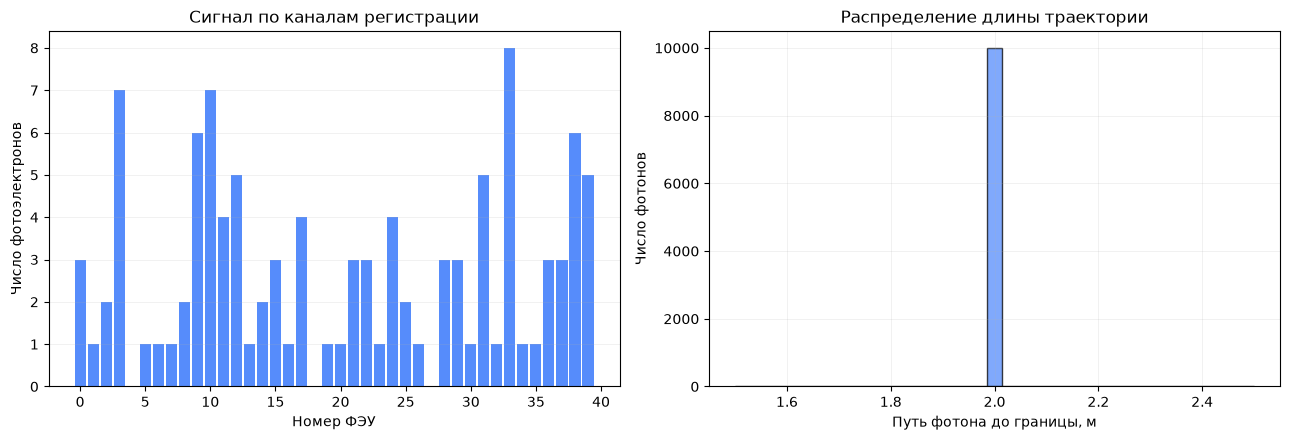

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(np.arange(detector.N), event["pmt_counts"], width=0.85)
axes[0].set(
    xlabel="Номер ФЭУ",
    ylabel="Число фотоэлектронов",
    title="Сигнал по каналам регистрации",
)
axes[0].grid(axis="y", alpha=0.25)

axes[1].hist(event["path_lengths"], bins=35, edgecolor="black", alpha=0.75)
axes[1].set(
    xlabel="Путь фотона до границы, м",
    ylabel="Число фотонов",
    title="Распределение длины траектории",
)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 15. Обязательная 3D-визуализация детектора в K3D

На интерактивной сцене отображаются:
- полупрозрачная сферическая граница детектора;
- все фотокатоды;
- точка рождения события;
- выборка траекторий фотонов: зелёные линии заканчиваются на ФЭУ, красные — на непокрытой части поверхности;
- точки попадания выбранных фотонов.

Для читаемости показывается ограниченная случайная выборка траекторий, но статистика и полный заряд выше рассчитаны по **всем** фотонам события. Если `k3d` ещё не установлен, выполните `%pip install k3d`, затем перезапустите kernel и ячейки ноутбука.

In [42]:
# K3D обязателен для выполнения визуализационной части задачи.
try:
    import k3d
except ImportError as exc:
    raise ImportError(
        "Для обязательной 3D-визуализации установите K3D: %pip install k3d, "
        "затем перезапустите kernel."
    ) from exc


def visualize_event_k3d(
    detector: Detector,
    event_result: dict,
    max_tracks: int = 500,
):
    """Интерактивная 3D-сцена детектора и выборки фотонных траекторий."""
    plot = detector.build_plot()

    rng = np.random.default_rng(12345)
    n = event_result["n_photons"]
    selected = np.arange(n)
    if n > max_tracks:
        selected = np.sort(rng.choice(n, size=max_tracks, replace=False))

    origin = event_result["origin"]
    hits = event_result["hit_points"]
    pmt_idx = event_result["pmt_indices"]

    detected = selected[pmt_idx[selected] >= 0]
    missed = selected[pmt_idx[selected] < 0]

    def add_segments(indices, color):
        nonlocal plot
        if len(indices) == 0:
            return
        vertices = np.empty((2 * len(indices), 3), dtype=np.float32)
        vertices[0::2] = origin
        vertices[1::2] = hits[indices]
        line_indices = np.arange(2 * len(indices), dtype=np.uint32).reshape(-1, 2)
        plot += k3d.lines(
            vertices,
            indices=line_indices,
            color=color,
            width=0.35,
        )

    # Отдельные цвета для зарегистрированных и не зарегистрированных фотонов.
    add_segments(detected, 0x00cc66)
    add_segments(missed, 0xdd4444)

    # Точка рождения события.
    plot += k3d.points(
        positions=np.asarray([origin], dtype=np.float32),
        point_size=0.18,
        color=0xffffff,
        shader="3d",
    )

    # Точки пересечения выбранных лучей с поверхностью.
    if len(detected):
        plot += k3d.points(
            positions=hits[detected].astype(np.float32),
            point_size=0.055,
            color=0x00ff88,
            shader="3d",
        )
    if len(missed):
        plot += k3d.points(
            positions=hits[missed].astype(np.float32),
            point_size=0.035,
            color=0xff5555,
            shader="3d",
        )

    plot.camera_auto_fit = True
    return plot


event_plot = visualize_event_k3d(detector, event, max_tracks=500)
event_plot

## 16. Статистическая проверка полного заряда

Один запуск содержит флуктуации Пуассона. Для оценки согласия с математическим ожиданием проведём серию независимых событий и сравним выборочное среднее с геометрическим ожиданием. Чтобы не выполнять визуализацию многократно, в цикле считаем только статистику детектирования.

Число событий:                  300
Средний заряд по моделированию: 124.42 p.e.
СКО между событиями:            13.29 p.e.
Ожидание по точной геометрии:    125.08 p.e.
Ожидание по формуле задания:    500.00 p.e.


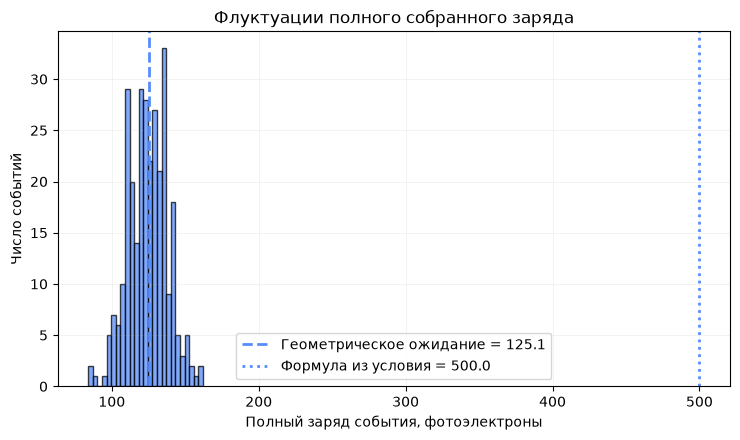

In [43]:
def simulate_total_charge_fast(
    detector: Detector,
    source: Source,
    energy_mev: float,
    a: float,
    rng: np.random.Generator,
) -> int:
    """Быстрый расчёт полного заряда серии событий без сохранения траекторий."""
    directions = source.generate_directions(energy_mev, rng=rng)
    # Для каждого фотона при источнике в центре точка попадания = R * direction.
    # Индекс ФЭУ определяется направлением, поскольку точка уже на сфере.
    cos_angles = directions @ detector.pmt_directions.T
    best = np.argmax(cos_angles, axis=1)
    covered = cos_angles[np.arange(len(directions)), best] >= np.cos(detector.theta_pmt)

    # Сумма независимых Poisson(a) по всем попавшим фотонам
    # эквивалентна Poisson(a * число попавших фотонов).
    n_hits = int(np.count_nonzero(covered))
    return int(rng.poisson(a * n_hits))


n_trials = 300
rng_trials = np.random.default_rng(314159)
charges = np.array([
    simulate_total_charge_fast(
        detector, source, EVENT_ENERGY_MEV, PHOTOELECTRON_MEAN, rng_trials
    )
    for _ in range(n_trials)
])

print(f"Число событий:                  {n_trials}")
print(f"Средний заряд по моделированию: {charges.mean():.2f} p.e.")
print(f"СКО между событиями:            {charges.std(ddof=1):.2f} p.e.")
print(f"Ожидание по точной геометрии:    {q_geometry:.2f} p.e.")
print(f"Ожидание по формуле задания:    {q_given:.2f} p.e.")

plt.figure(figsize=(7.5, 4.5))
plt.hist(charges, bins=25, edgecolor="black", alpha=0.75)
plt.axvline(q_geometry, linestyle="--", linewidth=2,
            label=f"Геометрическое ожидание = {q_geometry:.1f}")
plt.axvline(q_given, linestyle=":", linewidth=2,
            label=f"Формула из условия = {q_given:.1f}")
plt.xlabel("Полный заряд события, фотоэлектроны")
plt.ylabel("Число событий")
plt.title("Флуктуации полного собранного заряда")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 17. Выводы по задаче 3

Реализован полный алгоритм геометрического распространения фотонов и их регистрации:
- аналитически находится первое пересечение траектории со сферой;
- по точке пересечения определяется фотокатод, если он покрывает эту точку;
- для каждого попавшего фотона разыгрывается число фотоэлектронов $N_{pe}\sim\mathrm{Poisson}(a)$;
- суммирование по каналам даёт полный собранный заряд.

Метод генерации фотоэлектронов принадлежит `Photomultiplier`, так как описывает статистический отклик фотокатода. Метод `find_pmt_at_hit` относится к геометрии `Detector`, а генерация начальных направлений — к `Source`.

**Интерпретация сравнения с формулой из условия:** результат одного события не обязан совпадать с математическим ожиданием из-за флуктуаций числа фотонов, попаданий и фотоэлектронов. Для сравнения ожиданий следует использовать серию событий. Кроме того, при принятой геометрии фотокатодов естественное геометрическое покрытие сферы содержит множитель $1/4$; формула $Q=aY(Nr^2/R^2)$, приведённая в задании, в четыре раза больше приближения, следующего из площади фотокатодов на сферической поверхности. Это различие явно показано в расчётах.

# Задача 4. Энергетический отклик детектора

В этой части исследуем распределение полного собранного заряда при фиксированной энергии события и при изменении энергии. Также проверим влияние смещения источника на 1 м вдоль оси $z$.

План расчёта:
1. Смоделировать 1000 независимых событий с энергией 1 МэВ в центре детектора.
2. Повторить расчёт для энергий $0.2,\ 0.5,\ 0.7,\ 1.5,\ 2.0,\ 3.0$ МэВ.
3. Построить гистограммы полного заряда и вычислить среднее, стандартное отклонение и относительную ширину $\sigma_Q/\langle Q\rangle$.
4. Смоделировать 1000 событий с энергией 1 МэВ для источника в точке $(0,0,1)$ м.
5. Сравнить средние заряды для центрального и смещённого источников.

Для ускорения серии событий используется векторизованный расчёт геометрии. Статистическая модель остаётся той же, что в задаче 3: каждый фотон независимо попадает либо не попадает на фотокатод; при попадании число фотоэлектронов имеет распределение Пуассона с параметром $a$. Сумма независимых пуассоновских величин также распределена по Пуассону, поэтому полный заряд одного события можно разыграть как $\operatorname{Poisson}(aN_{hit})$.

## 18. Векторизованное моделирование серии событий

В отличие от полного пошагового моделирования одного события, здесь не требуется сохранять траекторию каждого фотона и распределение фотоэлектронов по каналам. Для каждого события достаточно определить количество фотонов, попавших на фотокатоды, а затем разыграть полный заряд.

Пересечение луча со сферой рассчитывается по той же формуле, что и в задаче 3. Расчёт выполняется небольшими пакетами событий, чтобы ограничить потребление оперативной памяти.

In [44]:
def simulate_charge_ensemble(
    detector: Detector,
    source: Source,
    energy_mev: float,
    n_events: int = 1000,
    origin=(0.0, 0.0, 0.0),
    a: float = 0.5,
    seed: int = 12345,
    batch_events: int = 8,
) -> tuple[np.ndarray, np.ndarray]:
    """Смоделировать распределение полного заряда для серии событий.

    Возвращает
    ----------
    charges : ndarray, shape (n_events,)
        Полный заряд каждого события в фотоэлектронах.
    hit_counts : ndarray, shape (n_events,)
        Число фотонов, попавших на фотокатоды в каждом событии.
    """
    origin = np.asarray(origin, dtype=float)
    if origin.shape != (3,) or not np.all(np.isfinite(origin)):
        raise ValueError("origin должен быть конечным вектором длины 3.")
    if np.linalg.norm(origin) >= detector.R:
        raise ValueError("Источник должен находиться строго внутри детектора.")
    if not isinstance(n_events, (int, np.integer)) or n_events <= 0:
        raise ValueError("n_events должен быть положительным целым числом.")
    if batch_events <= 0:
        raise ValueError("batch_events должен быть положительным.")
    if not np.isfinite(a) or a < 0:
        raise ValueError("Параметр a должен быть конечным и неотрицательным.")

    rng = np.random.default_rng(seed)
    n_photons = source.photon_count(energy_mev)
    charges = np.empty(n_events, dtype=np.int64)
    hit_counts = np.empty(n_events, dtype=np.int64)

    pmt_threshold = np.cos(detector.theta_pmt)
    pmt_axes_transposed = detector.pmt_directions.T
    origin_norm2 = float(np.dot(origin, origin))

    for start in range(0, n_events, batch_events):
        stop = min(start + batch_events, n_events)
        current_batch = stop - start

        # Изотропные направления: phi ~ U(0, 2pi), cos(theta) ~ U(-1, 1).
        phi = rng.uniform(0.0, 2.0 * np.pi, size=(current_batch, n_photons))
        mu = rng.uniform(-1.0, 1.0, size=(current_batch, n_photons))
        transverse = np.sqrt(np.maximum(0.0, 1.0 - mu**2))

        directions = np.empty((current_batch, n_photons, 3), dtype=np.float32)
        directions[..., 0] = transverse * np.cos(phi)
        directions[..., 1] = transverse * np.sin(phi)
        directions[..., 2] = mu

        # Первое пересечение луча x(t) = origin + t*n со сферой.
        projection = np.einsum("bpi,i->bp", directions, origin)
        discriminant = projection**2 + detector.R**2 - origin_norm2
        distance = -projection + np.sqrt(np.maximum(discriminant, 0.0))

        hit_points = origin + distance[..., None] * directions
        hit_directions = hit_points / detector.R

        # Фотон зарегистрирован, если его направление на границе
        # находится внутри угловой шапочки хотя бы одного ФЭУ.
        cosine_to_pmts = hit_directions @ pmt_axes_transposed
        is_detected = np.max(cosine_to_pmts, axis=-1) >= pmt_threshold
        batch_hits = np.count_nonzero(is_detected, axis=1)

        hit_counts[start:stop] = batch_hits
        # Сумма N_hit независимых Poisson(a) величин имеет закон Poisson(a*N_hit).
        charges[start:stop] = rng.poisson(a * batch_hits)

    return charges, hit_counts


## 19. 1000 событий с энергией 1 МэВ в центре детектора

Сначала выполняем базовый расчёт, указанный в первом пункте задачи. Фиксируем seed для воспроизводимости серии.

In [45]:
N_EVENTS = 1000
BASE_ENERGY_MEV = 1.0
CENTER_ORIGIN = (0.0, 0.0, 0.0)

charges_1MeV, hits_1MeV = simulate_charge_ensemble(
    detector=detector,
    source=source,
    energy_mev=BASE_ENERGY_MEV,
    n_events=N_EVENTS,
    origin=CENTER_ORIGIN,
    a=PHOTOELECTRON_MEAN,
    seed=41001,
)

mean_1MeV = charges_1MeV.mean()
std_1MeV = charges_1MeV.std(ddof=1)
relative_width_1MeV = std_1MeV / mean_1MeV

print(f"Количество событий:          {N_EVENTS}")
print(f"Средний полный заряд:        {mean_1MeV:.3f} p.e.")
print(f"Стандартное отклонение:      {std_1MeV:.3f} p.e.")
print(f"Относительная ширина sigma/mean: {relative_width_1MeV:.4f}")
print(f"Среднее число фотонов на ФЭУ: {hits_1MeV.mean():.3f}")

Количество событий:          1000
Средний полный заряд:        124.791 p.e.
Стандартное отклонение:      13.614 p.e.
Относительная ширина sigma/mean: 0.1091
Среднее число фотонов на ФЭУ: 249.515


### Распределение полного собранного заряда при 1 МэВ

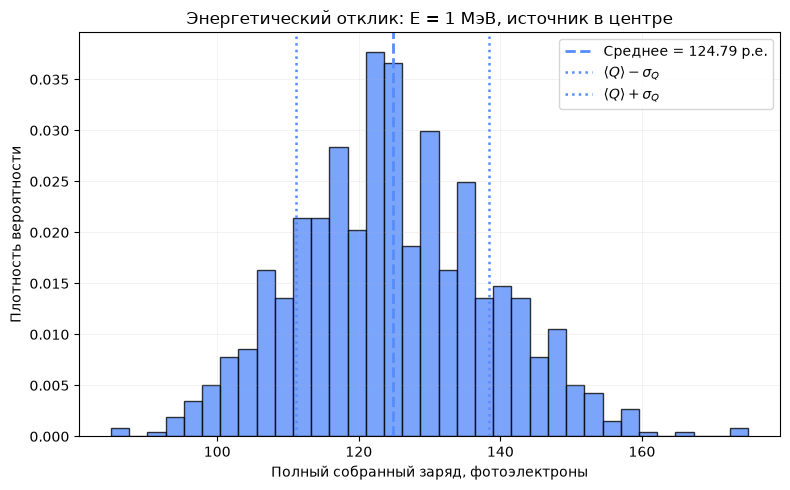

In [46]:
plt.figure(figsize=(8, 5))
plt.hist(charges_1MeV, bins=35, density=True, alpha=0.78, edgecolor="black")
plt.axvline(mean_1MeV, linestyle="--", linewidth=2,
            label=f"Среднее = {mean_1MeV:.2f} p.e.")
plt.axvline(mean_1MeV - std_1MeV, linestyle=":", linewidth=1.8,
            label=r"$\langle Q\rangle-\sigma_Q$")
plt.axvline(mean_1MeV + std_1MeV, linestyle=":", linewidth=1.8,
            label=r"$\langle Q\rangle+\sigma_Q$")
plt.xlabel("Полный собранный заряд, фотоэлектроны")
plt.ylabel("Плотность вероятности")
plt.title("Энергетический отклик: E = 1 МэВ, источник в центре")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 20. Зависимость распределения заряда от энергии

Повторяем моделирование для энергий из условия: $0.2,\ 0.5,\ 0.7,\ 1.5,\ 2.0,\ 3.0$ МэВ. Для сопоставимости используем по 1000 событий на каждую энергию. Центральная точка $(0,0,0)$ остаётся неизменной.

In [47]:
ENERGIES_MEV = [0.2, 0.5, 0.7, 1.5, 2.0, 3.0]
energy_results = {}

for index, energy_value in enumerate(ENERGIES_MEV):
    charges, hit_counts = simulate_charge_ensemble(
        detector=detector,
        source=source,
        energy_mev=energy_value,
        n_events=N_EVENTS,
        origin=CENTER_ORIGIN,
        a=PHOTOELECTRON_MEAN,
        seed=42000 + index,
    )
    energy_results[energy_value] = {
        "charges": charges,
        "hit_counts": hit_counts,
        "mean": float(charges.mean()),
        "std": float(charges.std(ddof=1)),
        "relative_width": float(charges.std(ddof=1) / charges.mean()),
    }

print("Энергия [МэВ] | Средний заряд [p.e.] | sigma [p.e.] | sigma/mean")
print("-" * 68)
for energy_value in ENERGIES_MEV:
    result = energy_results[energy_value]
    print(
        f"{energy_value:12.1f} | {result['mean']:19.3f} | "
        f"{result['std']:11.3f} | {result['relative_width']:10.4f}"
    )

Энергия [МэВ] | Средний заряд [p.e.] | sigma [p.e.] | sigma/mean
--------------------------------------------------------------------
         0.2 |              25.206 |       6.225 |     0.2470
         0.5 |              62.421 |       9.484 |     0.1519
         0.7 |              87.293 |      11.719 |     0.1343
         1.5 |             186.804 |      16.762 |     0.0897
         2.0 |             249.604 |      19.555 |     0.0783
         3.0 |             374.665 |      24.061 |     0.0642


### Гистограммы для всех энергий

Каждая панель соответствует 1000 независимым событиям. Общая нормировка по плотности позволяет сравнивать форму распределений, несмотря на различный масштаб заряда.

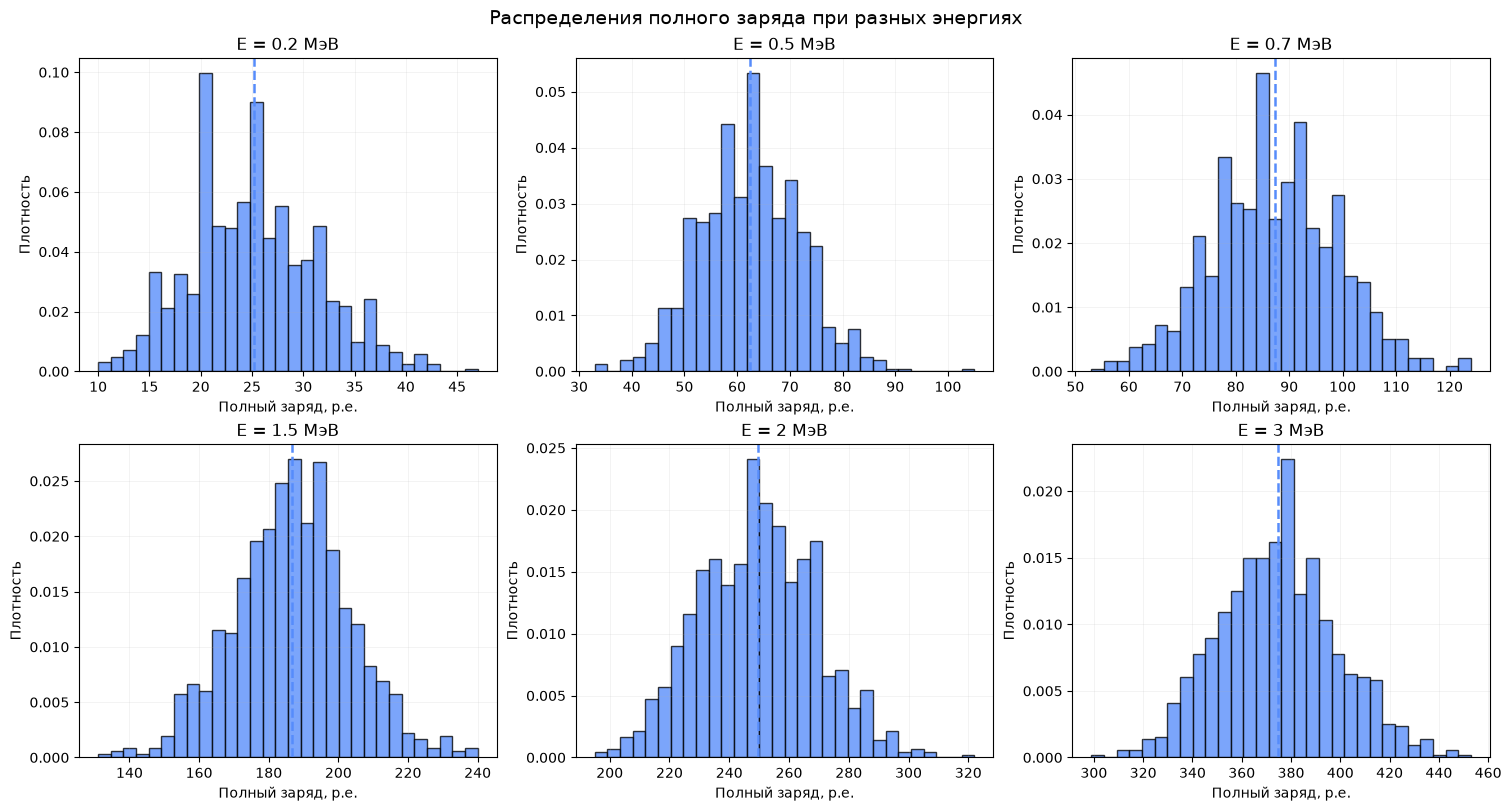

In [48]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, energy_value in zip(axes.flat, ENERGIES_MEV):
    result = energy_results[energy_value]
    ax.hist(result["charges"], bins=30, density=True,
            alpha=0.78, edgecolor="black")
    ax.axvline(result["mean"], linestyle="--", linewidth=1.8)
    ax.set_title(f"E = {energy_value:g} МэВ")
    ax.set_xlabel("Полный заряд, p.e.")
    ax.set_ylabel("Плотность")
    ax.grid(alpha=0.2)

fig.suptitle("Распределения полного заряда при разных энергиях", fontsize=14)
plt.show()

### Средний заряд и относительная ширина

Относительная ширина определяется как
$$
\frac{\sigma_Q}{\langle Q\rangle}.
$$
При увеличении энергии испускается больше фотонов и в среднем регистрируется больше фотоэлектронов. Поэтому относительные статистические флуктуации должны уменьшаться.

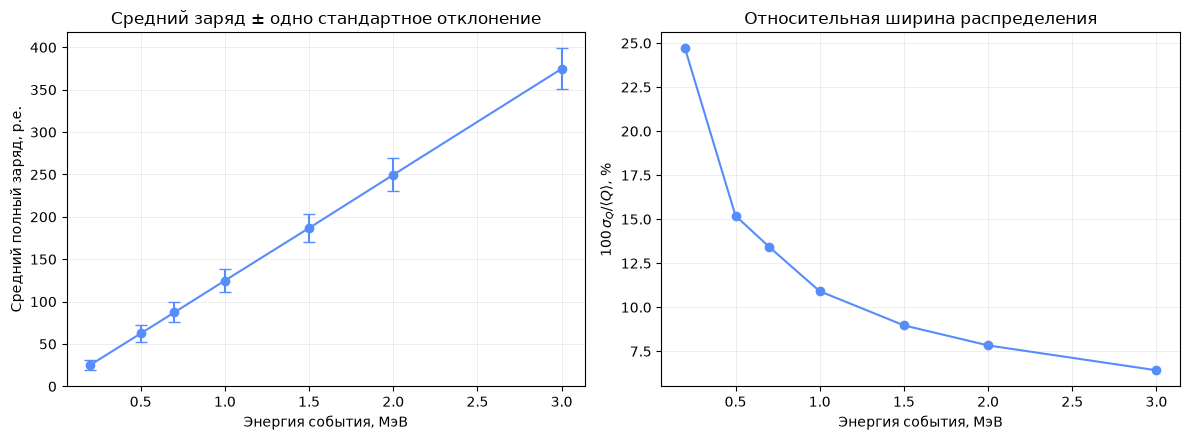

In [49]:
all_energies = [BASE_ENERGY_MEV] + ENERGIES_MEV
all_means = [mean_1MeV] + [energy_results[e]["mean"] for e in ENERGIES_MEV]
all_stds = [std_1MeV] + [energy_results[e]["std"] for e in ENERGIES_MEV]
all_rel_widths = [relative_width_1MeV] + [
    energy_results[e]["relative_width"] for e in ENERGIES_MEV
]

order = np.argsort(all_energies)
energies_sorted = np.asarray(all_energies)[order]
means_sorted = np.asarray(all_means)[order]
stds_sorted = np.asarray(all_stds)[order]
rel_sorted = np.asarray(all_rel_widths)[order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].errorbar(energies_sorted, means_sorted, yerr=stds_sorted,
                 fmt="o-", capsize=4)
axes[0].set(
    xlabel="Энергия события, МэВ",
    ylabel="Средний полный заряд, p.e.",
    title="Средний заряд ± одно стандартное отклонение",
)
axes[0].grid(alpha=0.3)

axes[1].plot(energies_sorted, 100 * rel_sorted, "o-")
axes[1].set(
    xlabel="Энергия события, МэВ",
    ylabel=r"$100\,\sigma_Q/\langle Q\rangle$, %",
    title="Относительная ширина распределения",
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 21. Смещение источника на 1 м вдоль оси z

Теперь сравним центральный источник с источником в точке
$$
\mathbf{x}_0=(0,0,1)\ \text{м}.
$$
Радиус детектора равен 2 м, поэтому смещённый источник остаётся внутри активного объёма.

При смещении источника изотропное излучение сохраняется, но фотоумножители видны из точки рождения под разными телесными углами. Поэтому вероятность попадания фотона на фотокатод и средний собранный заряд могут измениться. Выполним по 1000 событий для обеих конфигураций.

In [50]:
OFFSET_ORIGIN = (0.0, 0.0, 1.0)

charges_offset, hits_offset = simulate_charge_ensemble(
    detector=detector,
    source=source,
    energy_mev=BASE_ENERGY_MEV,
    n_events=N_EVENTS,
    origin=OFFSET_ORIGIN,
    a=PHOTOELECTRON_MEAN,
    seed=43001,
)

mean_offset = charges_offset.mean()
std_offset = charges_offset.std(ddof=1)
relative_offset = std_offset / mean_offset

mean_change = mean_offset - mean_1MeV
percent_change = 100.0 * mean_change / mean_1MeV

print(f"Центральный источник: mean = {mean_1MeV:.3f} p.e., sigma = {std_1MeV:.3f} p.e.")
print(f"Смещённый источник:   mean = {mean_offset:.3f} p.e., sigma = {std_offset:.3f} p.e.")
print(f"Изменение среднего:   {mean_change:+.3f} p.e. ({percent_change:+.2f}%)")
print(f"Относительная ширина, центр:   {relative_width_1MeV:.4f}")
print(f"Относительная ширина, смещение: {relative_offset:.4f}")

Центральный источник: mean = 124.791 p.e., sigma = 13.614 p.e.
Смещённый источник:   mean = 125.545 p.e., sigma = 13.277 p.e.
Изменение среднего:   +0.754 p.e. (+0.60%)
Относительная ширина, центр:   0.1091
Относительная ширина, смещение: 0.1058


### Сравнение распределений для центрального и смещённого источников

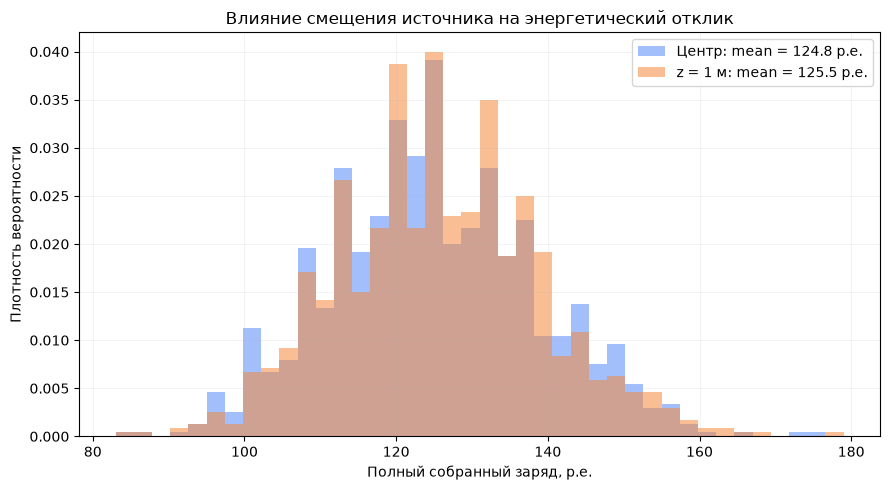

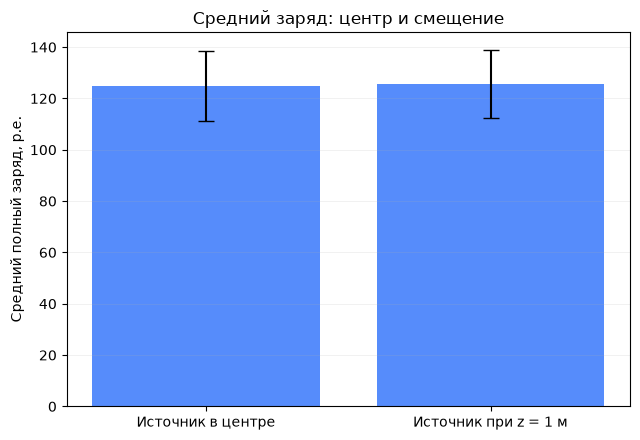

In [51]:
plt.figure(figsize=(9, 5))
bins = np.histogram_bin_edges(
    np.concatenate([charges_1MeV, charges_offset]), bins=40
)
plt.hist(charges_1MeV, bins=bins, density=True, alpha=0.55,
         label=f"Центр: mean = {mean_1MeV:.1f} p.e.")
plt.hist(charges_offset, bins=bins, density=True, alpha=0.55,
         label=f"z = 1 м: mean = {mean_offset:.1f} p.e.")
plt.xlabel("Полный собранный заряд, p.e.")
plt.ylabel("Плотность вероятности")
plt.title("Влияние смещения источника на энергетический отклик")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6.5, 4.5))
plt.bar(
    ["Источник в центре", "Источник при z = 1 м"],
    [mean_1MeV, mean_offset],
    yerr=[std_1MeV, std_offset],
    capsize=6,
)
plt.ylabel("Средний полный заряд, p.e.")
plt.title("Средний заряд: центр и смещение")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 22. K3D: визуализация детектора со смещённым источником

Покажем работу детектора для смещённого источника. Используется одно полноценное событие с энергией 1 МэВ и координатами $(0,0,1)$ м. Как и ранее, в 3D отображается выборка фотонных траекторий; все статистические результаты выше получены по полным сериям из 1000 событий.

In [52]:
offset_event = simulate_event(
    detector=detector,
    source=source,
    energy_mev=BASE_ENERGY_MEV,
    origin=OFFSET_ORIGIN,
    a=PHOTOELECTRON_MEAN,
    seed=43002,
)

print(f"Источник: {offset_event['origin']} м")
print(f"Испущено фотонов: {offset_event['n_photons']:,}")
print(f"Попало на фотокатоды: {offset_event['detected_photons']:,}")
print(f"Полный заряд этого события: {offset_event['total_photoelectrons']:,} p.e.")

offset_event_plot = visualize_event_k3d(
    detector,
    offset_event,
    max_tracks=500,
)
offset_event_plot

Источник: [0. 0. 1.] м
Испущено фотонов: 10,000
Попало на фотокатоды: 274
Полный заряд этого события: 130 p.e.


## 23. Итоги задачи 4

Выполнено моделирование по 1000 событий:
- для энергии 1 МэВ в центре детектора;
- для энергий 0.2, 0.5, 0.7, 1.5, 2.0 и 3.0 МэВ в центре;
- для энергии 1 МэВ при смещении источника на 1 м вдоль оси $z$.

Для каждого набора получены распределения полного собранного заряда, среднее значение, стандартное отклонение и относительная ширина $\sigma_Q/\langle Q\rangle$.

**Физическая интерпретация.** В линейной модели световыхода средний заряд растёт приблизительно пропорционально энергии. При этом абсолютная ширина распределения растёт примерно как квадратный корень из среднего числа зарегистрированных фотоэлектронов, а относительная ширина уменьшается с энергией. Смещение источника меняет видимые телесные углы фотокатодов и, следовательно, геометрическую эффективность сбора света. Численное изменение среднего заряда определяется результатами моделирования, выведенными выше.

Для надёжного сравнения используйте средние по 1000 событий, а не заряд одного случайного события. K3D-сцены показывают геометрию, траектории и попадания для центрального и смещённого источников.